# Kalpa's new store, sized by the guesstimate: how many members could it sign up in its first year?

**Week 4, Tuesday, the TA-led lab, after chapter 10.** **Applies:** the guesstimate:
clarify, map, calculate, validate (chapter 6, notebook 06), and the one-slide answer: claim,
evidence, caveat, action (chapter 1, notebook 01), for what you bring back. Notebook 08
sized Uber's evening-peak drivers at about 5,000 to 5,700 and checked the chain like for
like against the case's own driver-hours per trip.

**The question.** Anand Iyer, Kalpa Retail's finance controller, is deciding whether to fund
a new store, and before the data exists he wants a rough number, sized in fifteen minutes
from stated assumptions: how many customers it could sign up to Retail-Plus, Kalpa's paid
membership tier, in its first year. A sign-up is a new paying member whose home store is
the new one.

**Who needs the answer.** Anand, who funds or does not fund the store, and who will ask how
you know your number is not wildly off.

**The questions on the way.** What exactly is counted? Which chain gives sign-ups, and
which link can a published number check? Which store count turns DMart's revenue into a
year per store? Which guess sets your range?

This notebook sets up the tools and the published anchor; the sizing is yours, in the empty
cells.

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

anchor = pd.read_csv("../data/C2_W04_D02_kalpa_dmart_anchor_STUDENT.csv")
print(anchor.iloc[:4].to_string(index=False))          # the published figures, with their source
a = anchor.set_index("item").value
check("the opening count is the closing count less the stores added",
      a["Stores at 31 March 2025"] == a["Stores at 31 March 2026"] - a["Stores added in FY26"])

                                   item   value                                                                  note
FY26 standalone total revenue, Rs crore 66968.0 Avenue Supermarts press release, 2 May 2026 (checked 12 October 2026)
                Stores at 31 March 2026   500.0                                                      the same release
                   Stores added in FY26    85.0                                                      the same release
                Stores at 31 March 2025   415.0                                                 500 less the 85 added
PASS the opening count is the closing count less the stores added


## Which store count turns DMart's revenue into a year per store?

DMart, a large grocery chain, publishes its revenue and its store counts; nobody publishes
how many members a new store signs up. The table above comes from Avenue Supermarts, the
company that runs DMart: its standalone revenue is DMart's own business without its
subsidiaries, and FY26 is its financial year from 1 April 2025 to 31 March 2026. A year's
revenue was earned by the stores open across the year, and DMart opened 85 stores during
FY26, so the count at the year's end
overstates the stores that sold all year. The fair count for a year is the average of the
opening and closing counts.

stores: 415 at the start of FY26, 500 at its end, 457.5 on average
PASS the average count is 457.5
PASS the year-end count overstates the stores that sold all year


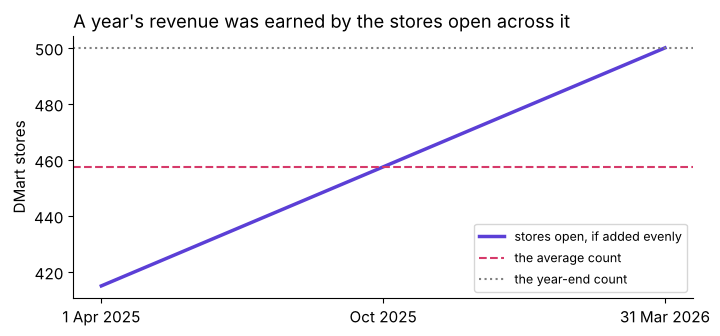

In [2]:
opening, closing = a["Stores at 31 March 2025"], a["Stores at 31 March 2026"]
average_count = (opening + closing) / 2
print(f"stores: {opening:.0f} at the start of FY26, {closing:.0f} at its end, {average_count} on average")
check("the average count is 457.5", average_count == 457.5)
check("the year-end count overstates the stores that sold all year", closing > average_count)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot([0, 12], [opening, closing], color=VIOLET, lw=2.5, label="stores open, if added evenly")
ax.axhline(average_count, color=ROSE, ls="--", label="the average count")
ax.axhline(closing, color="gray", ls=":", label="the year-end count")
ax.set_xticks([0, 6, 12], ["1 Apr 2025", "Oct 2025", "31 Mar 2026"])
ax.set_ylabel("DMart stores")
ax.set_title("A year's revenue was earned by the stores open across it", loc="left")
ax.legend(fontsize=9)
plt.show()

## Which chain gives sign-ups, and which link can a published number check?

**Clarify.** One new store, its first year, sign-ups counted as new paying members whose
home store is the new one. **Map.** Sign-ups = households near the store x the share who
shop there in year one x the share of those shoppers who sign up. The published anchor
reaches the first two links only: shoppers x visits a month x spend per visit x 12 is the
store's first-year sales, which can be laid beside what a mature DMart store sells. The
sign-up share stays a stated guess.

The cell below runs notebook 06's chain and swing on whatever table `ledger` holds, here
notebook 06's canteen (invented), so the lines are proven before you run them on yours.

the answer at the central guesses: 2,700
                                   low    high
students on campus              2430.0  2970.0
cups each buyer drinks          2025.0  3375.0
share who buy tea on a weekday  1500.0  3900.0


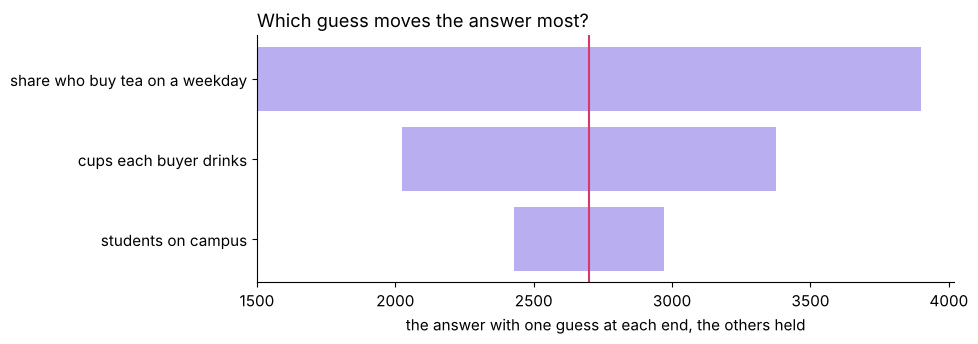

PASS the chain reproduces notebook 06's 2,700 cups
PASS the swing reproduces the share's 1,500 to 3,900
PASS every factor's low end gives a smaller answer than its high end


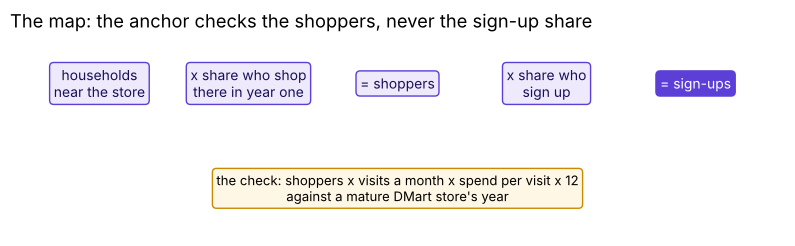

In [3]:
ledger = pd.read_csv("../data/C2_W04_D02_canteen_ledger_STUDENT.csv").set_index("factor")   # notebook 06's canteen

# the chain and the swing, notebook 06's lines: they run on whatever table ledger holds
central = ledger.central.prod()
rows = {}
for factor in ledger.index:
    ends = []
    for end in ("low", "high"):
        values = ledger.central.copy()
        values[factor] = ledger.loc[factor, end]
        ends.append(values.prod())
    rows[factor] = ends
sw = pd.DataFrame(rows, index=["low", "high"]).T
sw["width"] = sw.high - sw.low
sw = sw.sort_values("width")
print(f"the answer at the central guesses: {central:,.0f}")
print(sw[["low", "high"]].round(0).to_string())
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(sw.index, sw.width, left=sw.low, color=LILAC)
ax.axvline(central, color=ROSE)
ax.set_xlabel("the answer with one guess at each end, the others held")
ax.set_title("Which guess moves the answer most?", loc="left")
plt.show()

check("the chain reproduces notebook 06's 2,700 cups", central == 2700)
check("the swing reproduces the share's 1,500 to 3,900",
      sw.loc["share who buy tea on a weekday", ["low", "high"]].tolist() == [1500, 3900])
check("every factor's low end gives a smaller answer than its high end", (sw.low <= sw.high).all())

fig, ax = plt.subplots(figsize=(10, 2.6))
boxes = ["households\nnear the store", "x share who shop\nthere in year one", "= shoppers",
         "x share who\nsign up", "= sign-ups"]
for i, label in enumerate(boxes):
    ax.text(i, 0.6, label, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round", fc=VIOLET if i == 4 else PALE, ec=VIOLET),
            color="white" if i == 4 else INK)
ax.text(2, 0.05, "the check: shoppers x visits a month x spend per visit x 12\nagainst a mature DMart store's year",
        ha="center", va="center", fontsize=9.5, bbox=dict(boxstyle="round", fc="#FFF7E6", ec=AMBER))
ax.set_xlim(-0.6, 4.6)
ax.set_ylim(-0.2, 0.85)
ax.axis("off")
ax.set_title("The map: the anchor checks the shoppers, never the sign-up share", loc="left")
plt.show()

**Your turn: size Anand's question.** Write your ledger with a central value, a low and a
high for each of the three factors and one line of why, then run the chain and the swing.
Type the lines into the empty cell below, with your own numbers in the blanks, then paste
under them the lines of the cell above from `central = ledger.central.prod()` down to the
first `plt.show()`, unchanged, and run the cell:

```python
ledger = pd.DataFrame([
    ("households near the store",        ___, ___, ___, "___"),
    ("share who shop there in year one", ___, ___, ___, "___"),
    ("share of shoppers who sign up",    ___, ___, ___, "___"),
], columns=["factor", "central", "low", "high", "why"]).set_index("factor")
check("every low sits below its central and every high above it",
      ((ledger.low <= ledger.central) & (ledger.central <= ledger.high)).all())
```

**Your turn: validate against DMart.** Turn your shoppers into a year of sales, then lay
them beside DMart's revenue per store on the average count. A store in its first year should
sell less than a mature store; an estimate above it means a guess is too high.

```python
shoppers = ledger.loc["households near the store", "central"] * ledger.loc["share who shop there in year one", "central"]
visits_a_month, spend_per_visit = ___, ___          # your guesses, each said aloud
first_year_crore = shoppers * visits_a_month * spend_per_visit * 12 / 1e7
dmart_per_store = a["FY26 standalone total revenue, Rs crore"] / average_count
print(f"first-year sales: Rs {first_year_crore:,.0f} crore; DMart per store: Rs {dmart_per_store:,.0f} crore")
check("the new store sells below a mature DMart store", first_year_crore < dmart_per_store)
```

## What do you bring back to Anand?

One slide in notebook 01's four parts, said in three minutes to the TA:

- **The claim:** your sign-ups as a range, and what Anand should do with it.
- **The evidence:** the chain's central value and the guess that sets the range, from your
  swing.
- **The caveat:** the DMart check reaches the shoppers and never the sign-up share, and a
  first-year store sells less than a mature one.
- **The action:** the number to count first, Kalpa's own sign-up rate at its existing
  stores, which would be the like-for-like anchor, and who signs.

The unguided exercise `exercises/unguided/C2_W04_D02_kalpa_store_STUDENT.md` asks the
anchor's two decisions in lettered items, and the lab set carries the ladder.